In [2]:
# Imports libraries

import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Initializes dataframe

AL_scan_df = pd.read_csv('raw_data/AL_CORRECTED_SCANPREDS.csv')
AL_scan_df['DateTime'] = pd.to_datetime(AL_scan_df['DateTime'])
AL_scan_df['DateTime'] = AL_scan_df['DateTime'].dt.tz_localize('UTC')

# Filters dates (optional)

start_date = '2025-01-01'
end_date = '2025-12-31'

AL_scan_data = AL_scan_df.loc[(AL_scan_df['DateTime'] >= start_date) & (AL_scan_df['DateTime'] <= end_date)]

# Use AL_scan_data for filtered dates
# Use AL_scan_df for the full date range (unfiltered)

C:\Users\sends\AppData\Local\Temp\ipykernel_41064\1293521815.py:12: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  AL_scan_df['DateTime'] = pd.to_datetime(AL_scan_df['DateTime'])


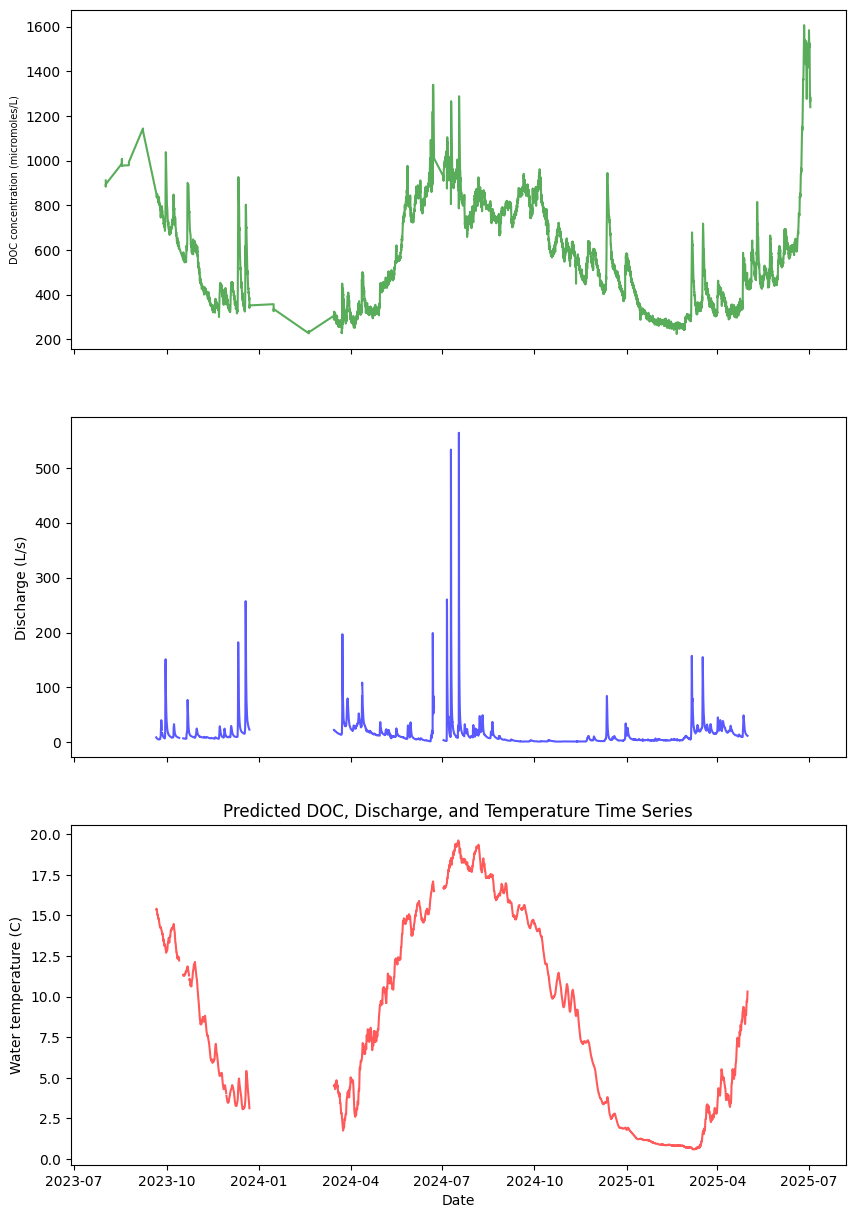

In [3]:
# Creates a multigraph of a temperature, discharge, and predicted DOC concentration 
# WITHOUT FILTERED DATES

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

index = AL_scan_df['DateTime']

ax1.plot(index, AL_scan_df['predicted_DOC'], color='green', alpha=0.65)
ax2.plot(index, AL_scan_df['AL discharge(L per second)'], color='blue', alpha=0.65)
ax3.plot(index, AL_scan_df['AL water temp (C) '], color='red', alpha=0.65)

ax1.set_ylabel('DOC concentration (micromoles/L)', fontsize=7)
ax2.set_ylabel('Discharge (L/s)')
ax3.set_ylabel('Water temperature (C)')

ax3.set_xlabel('Date')

plt.title('Predicted DOC, Discharge, and Temperature Time Series', loc='center')
plt.show()


C:\Users\sends\AppData\Local\Temp\ipykernel_41064\647147015.py:16: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(left=0.1, right=0.5, top=0.9, bottom=0.1)
C:\Users\sends\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


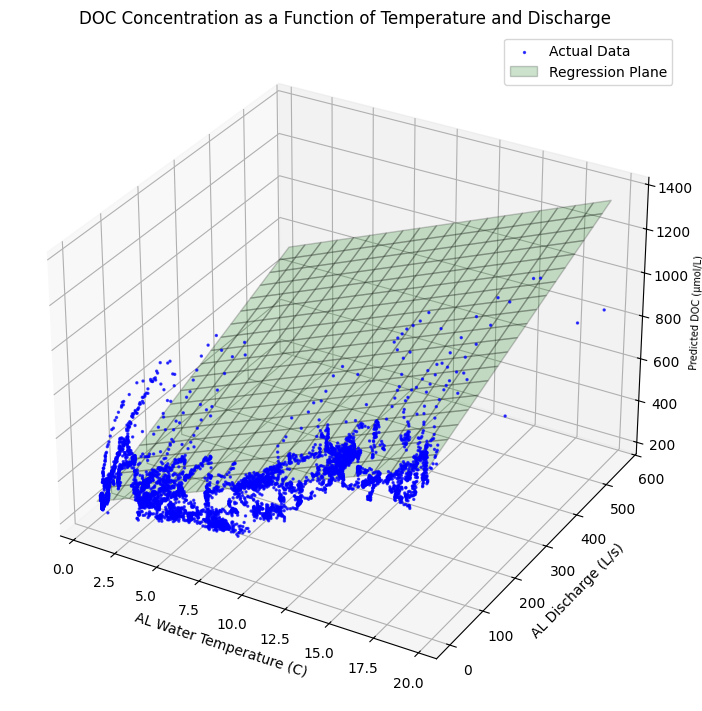

                            OLS Regression Results                            
Dep. Variable:          predicted_DOC   R-squared:                       0.761
Model:                            OLS   Adj. R-squared:                  0.761
Method:                 Least Squares   F-statistic:                     8659.
Date:                Tue, 05 Aug 2025   Prob (F-statistic):               0.00
Time:                        19:59:48   Log-Likelihood:                -33232.
No. Observations:                5441   AIC:                         6.647e+04
Df Residuals:                    5438   BIC:                         6.649e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
import statsmodels.api as sm

# Independent variables in X, dependent in 
# Common practice to have X capital for multiple independent variables
AL_scan_filtered = AL_scan_df.dropna()

X = AL_scan_filtered[['AL water temp (C) ','AL discharge(L per second)']]
y = AL_scan_filtered['predicted_DOC']

model = LinearRegression()
model.fit(X, y)

fig = plt.figure(figsize=(10, 7), constrained_layout=True)
plt.subplots_adjust(left=0.1, right=0.5, top=0.9, bottom=0.1)
ax = fig.add_subplot(projection='3d')

ax.scatter(AL_scan_filtered['AL water temp (C) '], AL_scan_filtered['AL discharge(L per second)'], AL_scan_filtered['predicted_DOC'],
           s=2, color='blue', alpha=0.7, label='Actual Data')
ax.set_xlabel('AL Water Temperature (C)')
ax.set_ylabel('AL Discharge (L/s)')
ax.set_zlabel('Predicted DOC (µmol/L)', fontsize=7, labelpad=3)


x_range = np.linspace(X.iloc[:, 0].min(), X.iloc[:, 0].max(), 20)
y_range = np.linspace(X.iloc[:, 1].min(), X.iloc[:, 1].max(), 20)
xx, yy = np.meshgrid(x_range, y_range)

grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict(grid).reshape(xx.shape)

ax.plot_surface(xx, yy, zz, alpha=0.2, color='green', edgecolor='k', label='Regression Plane')

plt.legend(loc='upper right')

plt.title('DOC Concentration as a Function of Temperature and Discharge')
plt.show()

X_sm = sm.add_constant(X)
ols_model = sm.OLS(y, X_sm).fit()

print(ols_model.summary()) # Gives R2 and p values which is pretty fire

# Next steps - plot DOC concentration as a function of water temperature and discharge SEPARATELY
# Make a residual plot of the multiple linear regression? 
# Make different plots based on the seasons
# Plot FDOM vs DOC and try to make a correction for pH